# 05 · Visualizations, insights and ethical reflection

**Research question:** What health, lifestyle, and environmental patterns are associated with children's screen-time levels?

**Scope:** interpret Tee's approved **Gower / complete linkage / equal feature weights (W0) / k = 3** results. The tree contains 10,000 children; 41,375 more children were assigned to the cluster with the smallest average Gower distance. Unless stated otherwise, profiles below describe all **51,375 survey records**, with equal weight per child.

The clusters are weakly separated and sensitive to feature weighting. They describe overlapping group tendencies, not diagnoses or fixed types of children. Screen time, age, and all substantive characteristics plotted below helped form the groups; their differences are **descriptive profiles, not independent validation**.

**Run:** start a Python kernel with pandas, NumPy, Matplotlib and IPython, then Run All from the repository root. This notebook reads existing exports only. Its five figures are saved under `outputs/visualization_insights/`. No clustering or model evaluation is rerun.

## 0 · Setup and configuration

Use project-relative paths and the team's numbered sections, short purpose comments, validation checks and Matplotlib plots. Notebook text and figure labels follow the team's English documentation style.

In [13]:
import json
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# ---- Configuration -------------------------------------------------------
ROOT = Path.cwd()
DATA_PATH = ROOT / "datasets" / "preprocessed_data.csv"
EXPORT_DIR = ROOT / "outputs"
FIG_DIR = EXPORT_DIR / "visualization_insights"
CLUSTERS = [1, 2, 3]
CLUSTER_NAMES = {c: f"Cluster {c}" for c in CLUSTERS}
CLUSTER_COLORS = ["#0072B2", "#D55E00", "#7B4E9B"]
MIN_N = 30
SAVED_FIGURES = []

plt.rcParams.update({"figure.figsize": (10, 6), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "savefig.dpi": 180})

def save_figure(fig, name, note):
    # Put the scope and limitations on the image so they survive reuse.
    fig.text(0.02, 0.025, note + "\nDescriptive clusters; weak separation and sensitivity to feature weighting.",
             ha="left", va="bottom", fontsize=9, color="#444444")
    fig.tight_layout(rect=(0, 0.14, 1, 1))
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / name
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    SAVED_FIGURES.append(path)
    plt.show()
    plt.close(fig)

print("Python", platform.python_version())
print("pandas", pd.__version__, "| NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)

Python 3.14.6
pandas 3.1.0 | NumPy 2.4.6 | Matplotlib 3.11.2


## 1 · Load and validate the approved results

**What:** join the processed records and the final labels one-to-one using `hhid`, never row position. Verify model settings, feature ranges, membership totals and the distinction between hierarchical and assigned records.

**Source reconciliation:** the introduction to notebook 03 still mentions average linkage as the planned method. Its later decision record, exported configuration and current results identify complete linkage as the approved model, which is used here.

In [14]:
df = pd.read_csv(DATA_PATH)
assignments = pd.read_csv(EXPORT_DIR / "cluster_assignments.csv")
profiles = pd.read_csv(EXPORT_DIR / "cluster_profiles.csv", dtype={"cluster": str})
evaluation = pd.read_csv(EXPORT_DIR / "evaluation_results.csv")
per_cluster = pd.read_csv(EXPORT_DIR / "per_cluster_silhouette.csv")
stability = pd.read_csv(EXPORT_DIR / "stability_sensitivity.csv")
with open(EXPORT_DIR / "model_config.json", encoding="utf-8") as fh:
    config = json.load(fh)

assert df["hhid"].is_unique and assignments["hhid"].is_unique
assert df["hhid"].notna().all() and assignments["hhid"].notna().all()
assert len(df) == len(assignments) == 51_375
assert set(df["hhid"]) == set(assignments["hhid"])
data = df.merge(assignments, on="hhid", validate="one_to_one")
assert set(data["cluster"]) == set(CLUSTERS)
assert config["model"]["linkage"] == "complete"
assert config["model"]["weighting"] == "W0" and config["model"]["k"] == 3
assert "Gower" in config["model"]["distance"]
assert config["sampling"]["sample_size"] == 10_000
assert config["sampling"]["strata"] == ["formtype", "screentime"]
assert config["sampling"]["seed"] == 42
assert set(data["assignment_method"]) == {"hierarchical", "assigned"}
assert data["in_clustering_sample"].equals(data["assignment_method"].eq("hierarchical"))
assert data["in_clustering_sample"].sum() == 10_000
assert np.isfinite(data["fwc"]).all() and data["fwc"].gt(0).all()

feature_spec = pd.DataFrame(config["features"])
assert len(feature_spec) == 14 and feature_spec["weight"].eq(1).all()
for row in feature_spec.itertuples(index=False):
    values = data[row.feature].dropna()
    assert values.between(row.min, row.max).all(), row.feature
    if row.feature != "sleep_below_minimum":
        assert data[row.feature].notna().all(), row.feature
structural_sleep = data["sc_age_years"].eq(0) & data["sc_age_lt4"].eq(1)
assert data["sleep_below_minimum"].isna().equals(structural_sleep)
assert structural_sleep.sum() == 446
assert not profiles.duplicated(["cluster", "statistic"]).any()

size_table = pd.crosstab(data["cluster"], data["assignment_method"]).reindex(CLUSTERS)
size_table = size_table[["hierarchical", "assigned"]]
size_table["total_n"] = size_table.sum(axis=1)
size_table["unweighted_share_pct"] = size_table["total_n"] / len(data) * 100
print("Validated 51,375 matched records; approved 14-feature model; no model run.")
display(size_table.round(2))

Validated 51,375 matched records; approved 14-feature model; no model run.


assignment_method,hierarchical,assigned,total_n,unweighted_share_pct
cluster,,,,
1,6833,26881,33714,65.62
2,2594,11883,14477,28.18
3,573,2611,3184,6.20


### 1.1 · Definitions and interpretation boundaries

Variable meanings were checked against the [2024 NSCH Topical Variable List](https://www2.census.gov/programs-surveys/nsch/technical-documentation/codebook/2024-NSCH-Topical-Variable-List.pdf) (PDF pages 24, 33, 44, 51 and 66). The raw `.dta` has no value-label dictionary, so its codes alone cannot verify category meanings.

| Variable | Interpretation used here | Role |
|---|---|---|
| `screentime` | Weekday recreational screen use, excluding schoolwork; ordered bands `<1 h`, `1 h`, `2 h`, `3 h`, `4+ h` | Clustering feature |
| `sc_age_years` | Age in completed years, 0–17 | Clustering feature |
| `k10q12`, `k10q13`, `k10q14` | Reported neighborhood park/playground, recreation/community center or club, library/bookmobile; code 1 = present | Three clustering features |
| `k4q22_r` | Past-year mental-health care: received (1), needed but not received (2), reported not needed (3) | Clustering feature |
| `k4q23` | Reported medication for emotional, concentration or behavioral difficulties; code 1 = yes | Clustering feature; not a diagnosis |
| `k6q71_r` | Learning curiosity: always (1) through never (4) | Clustering feature |
| `foodsit` | Food affordability; codes 3–4 indicate insufficient food affordability sometimes/often | Clustering feature |
| `sleep_below_minimum` | Existing age-based sleep indicator from notebook 01; 1 = below minimum, 0 = at/above; undefined for infants under 4 months | Clustering feature |
| `fwc`, `formtype`, imputation flags | Survey weighting, questionnaire context, preprocessing audit | Compared afterward; not independent outcomes |
| Assignment method/margin, silhouettes | How labels were obtained and their limitations | Model diagnostics, not child characteristics |

The other model features (`sc_sex`, `family_r`, `blindness`, `higrade`) remain part of the approved specification but are not additional chart topics. No health or lifestyle variable displayed here was held out from clustering. Age bands below are descriptive summaries of an existing feature.

**How similarity was defined:** notebook 03 divides numeric/ordinal differences by fixed codebook ranges and uses category mismatches for nominal/binary features. Gower averages those contributions with W0 weights of 1; unavailable sleep comparisons and shared negative responses for asymmetric binaries are omitted pairwise. Complete linkage merges using the largest between-group pairwise distance. The later assignment step uses average distance to sample members, which can produce different profile contrasts from the tree itself. Equal feature weights do not give equal total influence to each domain: three correlated amenity variables contribute separately.

**Denominators:** the main percentages include processed/imputed responses and use all eligible members within each cluster. Sleep excludes the 446 structurally undefined records. Weighted percentages divide the sum of `fwc` for the event by the sum for eligible cluster members; they do not refit the clusters. The existing `n >= 30` reporting rule is retained, but it does not guarantee precise estimates or privacy by itself. No confidence intervals or significance claims are made.

In [15]:
# ---- Reusable summaries, verified against Tee's exported profiles ---------
SCREEN_LABELS = {1: "<1 h", 2: "1 h", 3: "2 h", 4: "3 h", 5: "4+ h"}
SCREEN_STATS = {i: f"% screen time code {i}" + {1: " (<1 h)", 5: " (4+ h)"}.get(i, "")
                for i in SCREEN_LABELS}
EVENTS = {
    "Screen time 4+ h": ("screentime", [5], SCREEN_STATS[5]),
    "Park / playground": ("k10q12", [1], "% park or playground in neighborhood"),
    "Recreation / community center or club": ("k10q13", [1], "% recreation/community center in neighborhood"),
    "Library / bookmobile": ("k10q14", [1], "% library in neighborhood"),
    "Mental-health care received": ("k4q22_r", [1], "% mental-health treatment received (k4q22_r = 1)"),
    "Mental-health care needed, not received": ("k4q22_r", [2], "% mental-health care needed, not received (k4q22_r = 2)"),
    "Medication use": ("k4q23", [1], "% medication for emotions/concentration/behavior (k4q23 = 1)"),
    "Sleep below age minimum": ("sleep_below_minimum", [1], "% sleep below age minimum"),
    "Learning curiosity: always": ("k6q71_r", [1], "% curiosity in learning 'always' (k6q71_r = 1)"),
    "Sometimes/often cannot afford enough food": ("foodsit", [3, 4], "% food sometimes/often not enough (foodsit >= 3)"),
}

def event_summary(frame, column, levels):
    valid = frame[column].notna()
    n = int(valid.sum())
    event = frame.loc[valid, column].isin(levels)
    weights = frame.loc[valid, "fwc"]
    return {"n_used": n, "event_n": int(event.sum()), "weight_sum": float(weights.sum()),
            "unweighted_pct": event.mean() * 100 if n >= MIN_N else np.nan,
            "weighted_pct": np.average(event, weights=weights) * 100 if n >= MIN_N else np.nan}

rows = []
for c, group in data.groupby("cluster"):
    for label, (column, levels, stat) in EVENTS.items():
        rows.append({"cluster": c, "characteristic": label, "statistic": stat,
                     **event_summary(group, column, levels)})
event_table = pd.DataFrame(rows)
reference = profiles.set_index(["cluster", "statistic"])
for row in event_table.itertuples(index=False):
    expected = reference.loc[(str(row.cluster), row.statistic)]
    assert row.n_used == expected["n_used"]
    np.testing.assert_allclose([row.unweighted_pct, row.weighted_pct],
                               expected[["unweighted", "weighted"]].astype(float), atol=1e-10)

screen_counts = pd.crosstab(data["cluster"], data["screentime"]).reindex(index=CLUSTERS, columns=SCREEN_LABELS, fill_value=0)
screen_pct = screen_counts.div(size_table["total_n"], axis=0) * 100
np.testing.assert_allclose(screen_pct.sum(axis=1), 100)
for c in CLUSTERS:
    for level, stat in SCREEN_STATS.items():
        np.testing.assert_allclose(screen_pct.loc[c, level], reference.loc[(str(c), stat), "unweighted"], atol=1e-10)
    for stat, value in [("number of children", size_table.loc[c, "total_n"]),
                        ("% of all children", size_table.loc[c, "unweighted_share_pct"]),
                        ("mean age (years)", data.loc[data["cluster"].eq(c), "sc_age_years"].mean())]:
        np.testing.assert_allclose(value, reference.loc[(str(c), stat), "unweighted"], atol=1e-10)

print("Counts, age means, all five screen-time bands and 10 profile measures match the existing exports.")

Counts, age means, all five screen-time bands and 10 profile measures match the existing exports.


## 2 · Cluster sizes and membership provenance

Count both hierarchical and assigned children. Stacked segments show how membership was obtained, not an uncertainty interval. Percentages use all 51,375 records as the denominator.

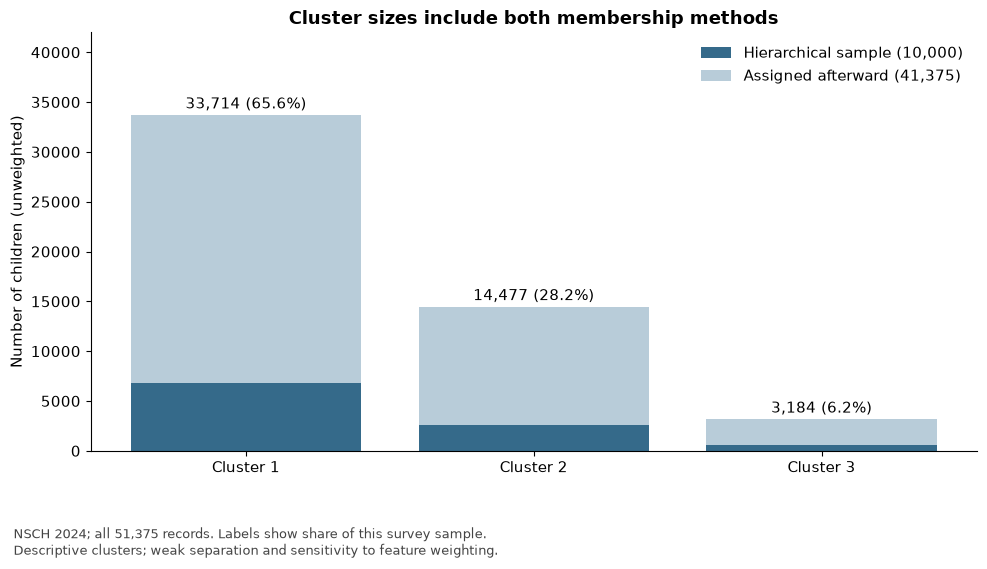

In [16]:
fig, ax = plt.subplots(figsize=(10, 5.8))
x = np.arange(3)
ax.bar(x, size_table["hierarchical"], color="#356A8A", label="Hierarchical sample (10,000)")
ax.bar(x, size_table["assigned"], bottom=size_table["hierarchical"], color="#B8CCD9", label="Assigned afterward (41,375)")
for i, c in enumerate(CLUSTERS):
    n = size_table.loc[c, "total_n"]
    ax.text(i, n + 650, f"{n:,} ({size_table.loc[c, 'unweighted_share_pct']:.1f}%)", ha="center")
ax.set(xticks=x, xticklabels=list(CLUSTER_NAMES.values()), ylim=(0, 42_000),
       ylabel="Number of children (unweighted)", title="Cluster sizes include both membership methods")
ax.legend(frameon=False, loc="upper right")
save_figure(fig, "01_cluster_sizes.png", "NSCH 2024; all 51,375 records. Labels show share of this survey sample.")

**Interpretation.** Cluster 1 contains 65.6% of records, Cluster 2 28.2%, and Cluster 3 6.2%. These are sample shares, not national prevalence. Cluster 3 is smaller but still contains 3,184 records, so its broad profile can be described without treating it as an anomaly or a clinical subgroup. Most membership comes from post-tree assignment; Section 6 checks whether that affects the description.

## 3 · Screen-time patterns alongside age

**What:** ordered screen-time bands and age-band composition, both as within-cluster percentages. Each bar sums to 100%. Screen-time codes are not exact hours, so no mean hours or boxplot of screen-time codes is used. Age means are shown in years as context, not as an adjustment for age.

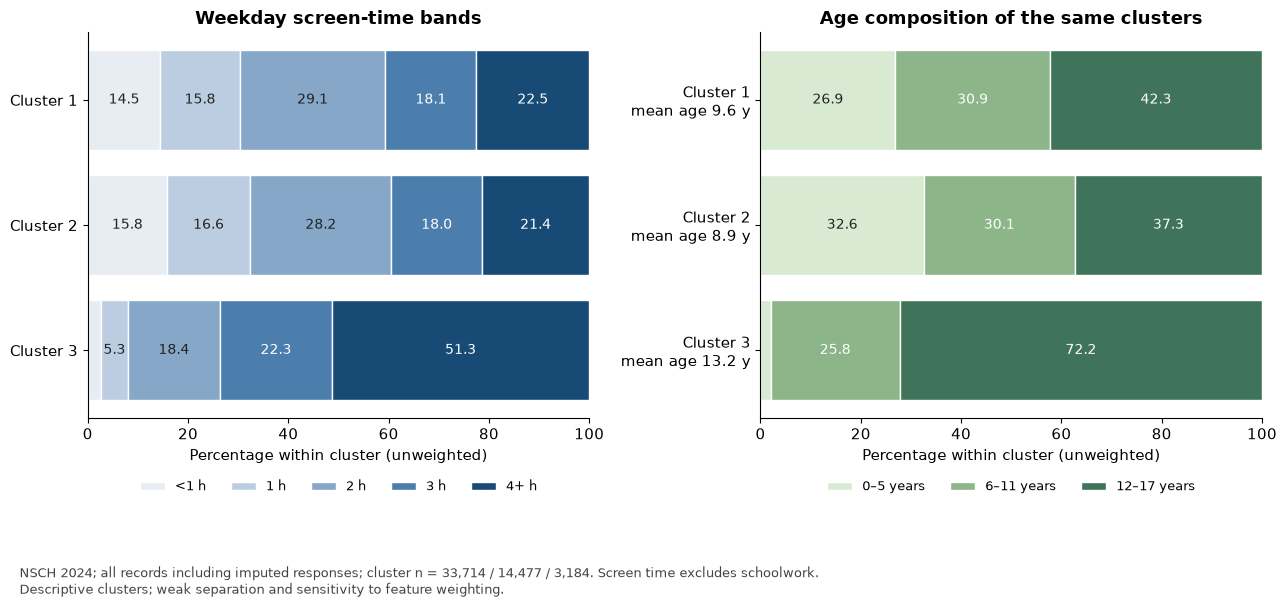

screentime,<1 h,1 h,2 h,3 h,4+ h
cluster,,,,,
1,14.49,15.81,29.07,18.12,22.52
2,15.80,16.60,28.16,18.04,21.40
3,2.67,5.31,18.40,22.30,51.32


In [17]:
AGE_LABELS = ["0–5 years", "6–11 years", "12–17 years"]
data["age_band"] = pd.cut(data["sc_age_years"], [-1, 5, 11, 17], labels=AGE_LABELS)
age_counts = pd.crosstab(data["cluster"], data["age_band"]).reindex(index=CLUSTERS, columns=AGE_LABELS)
age_pct = age_counts.div(size_table["total_n"], axis=0) * 100
np.testing.assert_allclose(age_pct.sum(axis=1), 100)
mean_age = data.groupby("cluster")["sc_age_years"].mean().reindex(CLUSTERS)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
screen_colors = ["#E8EDF3", "#BDCDE1", "#86A7C8", "#4B7EAC", "#174B75"]
for ax, table, labels, colors, title in [
    (axes[0], screen_pct, list(SCREEN_LABELS.values()), screen_colors, "Weekday screen-time bands"),
    (axes[1], age_pct, AGE_LABELS, ["#D9EAD3", "#8CB58A", "#3F745A"], "Age composition of the same clusters")
]:
    left = np.zeros(3)
    for j, (column, label, color) in enumerate(zip(table.columns, labels, colors)):
        values = table[column].to_numpy()
        ax.barh(np.arange(3), values, left=left, color=color, label=label, edgecolor="white")
        for i, v in enumerate(values):
            if v >= 5:
                ax.text(left[i] + v / 2, i, f"{v:.1f}", ha="center", va="center",
                        color="white" if j >= len(colors) - 2 else "#222222", fontsize=10)
        left += values
    ax.set(xlim=(0, 100), yticks=np.arange(3), yticklabels=list(CLUSTER_NAMES.values()),
           xlabel="Percentage within cluster (unweighted)", title=title)
    ax.invert_yaxis()
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=len(labels), frameon=False, fontsize=9)
axes[1].set_yticklabels([f"Cluster {c}\nmean age {mean_age[c]:.1f} y" for c in CLUSTERS])
save_figure(fig, "02_screen_time_and_age.png",
            "NSCH 2024; all records including imputed responses; cluster n = 33,714 / 14,477 / 3,184. Screen time excludes schoolwork.")
display(screen_pct.rename(columns=SCREEN_LABELS).round(2))

### Insight 1 · The higher-screen-time profile is also older

**Evidence:** 4+ hours is reported for 51.3% of Cluster 3, versus 22.5% and 21.4% in Clusters 1 and 2. Mean ages are 13.25, 9.64 and 8.94 years, respectively; 72.2% of Cluster 3 is aged 12–17.

**Meaning and relevance:** higher screen use co-occurs with a different age mix. This helps answer the research question as a combined profile of age, lifestyle and health, rather than a single screen-time category. Follow-up research should compare children at similar ages and ask about the content and context of screen use before proposing support.

**Limitations:** both age and screen time formed the clusters. These results cannot establish an independent effect of health, age or environment, nor show that one causes screen use. The following comparison checks broad age composition only; it is not causal adjustment or external validation.

In [18]:
# ---- Within-age comparison: use each cluster x age-band denominator -------
age_rows = []
for (c, band), group in data.groupby(["cluster", "age_band"], observed=True):
    age_rows.append({"cluster": c, "age_band": str(band), **event_summary(group, "screentime", [5])})
age_screen = pd.DataFrame(age_rows)
display(age_screen[["cluster", "age_band", "n_used", "event_n", "unweighted_pct"]]
        .rename(columns={"event_n": "n_screen_4plus", "unweighted_pct": "screen_4plus_pct"}).round(2))

,cluster,age_band,n_used,n_screen_4plus,screen_4plus_pct
0,1,0–5 years,9059,493,5.44
1,1,6–11 years,10401,1830,17.59
2,1,12–17 years,14254,5268,36.96
3,2,0–5 years,4718,313,6.63
4,2,6–11 years,4352,778,17.88
5,2,12–17 years,5407,2007,37.12
6,3,0–5 years,64,18,28.12
7,3,6–11 years,821,304,37.03
8,3,12–17 years,2299,1312,57.07


Among ages 12–17, 4+ hours remains more common in Cluster 3 (57.1%, n = 2,299) than in Clusters 1 and 2 (37.0%, n = 14,254; 37.1%, n = 5,407). The same ordering appears in the other broad age bands. Thus, age-band composition alone does not remove the descriptive contrast. Exact age, other characteristics, and the use of screen time to construct the labels still matter. Cluster 3 has only 64 children aged 0–5; that subgroup is not a sound basis for targeted recommendations.

## 4 · Neighborhood amenities and similar screen-time profiles

Plot the percentage reporting each amenity, not a combined access or neighborhood-quality score. Presence does not establish use, accessibility, safety or quality.

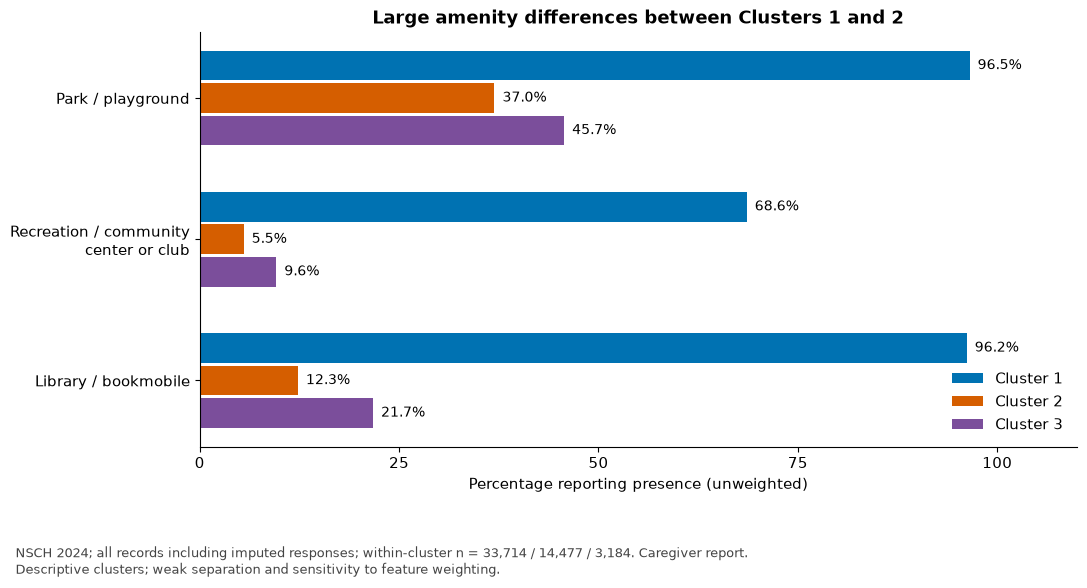

In [19]:
amenity_names = ["Park / playground", "Recreation / community center or club", "Library / bookmobile"]
amenity_table = event_table[event_table["characteristic"].isin(amenity_names)].pivot(
    index="characteristic", columns="cluster", values="unweighted_pct").reindex(amenity_names)
fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(amenity_names))
for i, c in enumerate(CLUSTERS):
    values = amenity_table[c].to_numpy()
    ypos = y + (i - 1) * 0.23
    ax.barh(ypos, values, height=0.21, color=CLUSTER_COLORS[i], label=CLUSTER_NAMES[c])
    for yy, v in zip(ypos, values):
        ax.text(v + 1, yy, f"{v:.1f}%", va="center", fontsize=10)
ax.set(yticks=y, yticklabels=["Park / playground", "Recreation / community\ncenter or club", "Library / bookmobile"],
       xlim=(0, 110), xticks=[0, 25, 50, 75, 100], xlabel="Percentage reporting presence (unweighted)",
       title="Large amenity differences between Clusters 1 and 2")
ax.invert_yaxis()
ax.legend(frameon=False, loc="lower right")
save_figure(fig, "03_neighborhood_amenities.png",
            "NSCH 2024; all records including imputed responses; within-cluster n = 33,714 / 14,477 / 3,184. Caregiver report.")

### Insight 2 · Amenity differences do not map onto a simple screen-time ordering

**Evidence:** Clusters 1 and 2 differ by 59.6 percentage points for parks/playgrounds (96.5% vs 37.0%), 63.1 points for recreation facilities (68.6% vs 5.5%), and 83.9 points for libraries/bookmobiles (96.2% vs 12.3%). Yet their 4+ hour shares differ by only 1.1 points (22.5% vs 21.4%), and each of the five screen-time bands differs by less than 1.4 points. Within each broad age band, their 4+ hour shares are also close.

**Meaning and relevance:** the approved partition separates neighborhood profiles much more strongly than it separates screen use between these two groups. The research question therefore has no simple answer such as “fewer amenities means more screen time.” A useful next inquiry is whether children actually use the reported amenities and whether access barriers exist; this analysis does not establish the effect of building a facility.

**Limitations:** the three correlated amenity inputs helped create the contrast. Existing sensitivity exports show ARI 0.042 when they are down-weighted and 0.044 when combined into one count (Section 6). The contrast is conditional on this feature specification. Descriptively similar percentages are not a formal equivalence test and do not establish that amenities have no relationship with screen use.

## 5 · Health and lifestyle characteristics

Use the same 0–100% axis for all measures. Treatment, medication and reported unmet need describe different responses, not diagnoses or a ranking of families. The sleep indicator uses the existing age-specific thresholds; its denominator differs from the other rows.

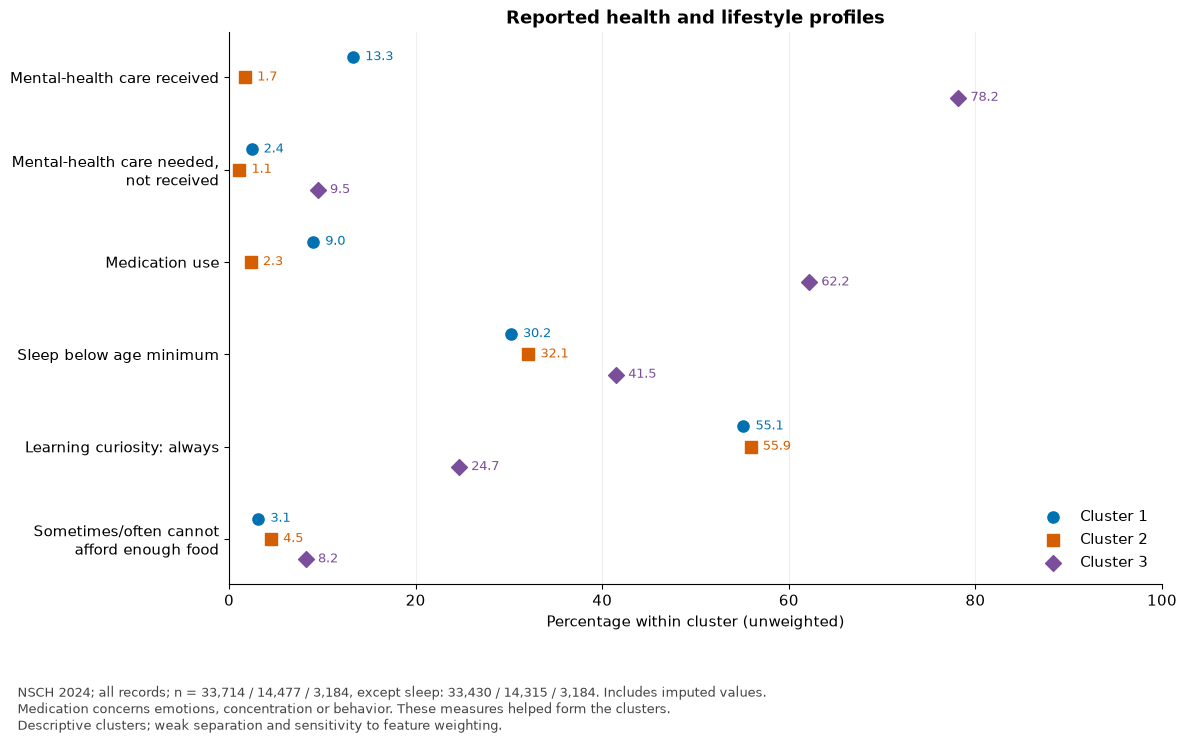

,cluster,characteristic,n_used,event_n,unweighted_pct
4,1,Mental-health care received,33714,4482,13.29
5,1,"Mental-health care needed, not received",33714,811,2.41
6,1,Medication use,33714,3038,9.01
7,1,Sleep below age minimum,33430,10097,30.20
8,1,Learning curiosity: always,33714,18585,55.13
9,1,Sometimes/often cannot afford enough food,33714,1056,3.13
14,2,Mental-health care received,14477,249,1.72
15,2,"Mental-health care needed, not received",14477,161,1.11
16,2,Medication use,14477,337,2.33
17,2,Sleep below age minimum,14315,4592,32.08


In [20]:
health_names = ["Mental-health care received", "Mental-health care needed, not received", "Medication use",
                "Sleep below age minimum", "Learning curiosity: always", "Sometimes/often cannot afford enough food"]
health = event_table[event_table["characteristic"].isin(health_names)]
health_wide = health.pivot(index="characteristic", columns="cluster", values="unweighted_pct").reindex(health_names)
tick_labels = ["Mental-health care received", "Mental-health care needed,\nnot received", "Medication use",
               "Sleep below age minimum", "Learning curiosity: always", "Sometimes/often cannot\nafford enough food"]
fig, ax = plt.subplots(figsize=(12, 7.6))
for i, c in enumerate(CLUSTERS):
    ypos = np.arange(len(health_names)) + (i - 1) * 0.22
    vals = health_wide[c].to_numpy()
    ax.scatter(vals, ypos, s=65, color=CLUSTER_COLORS[i], marker=["o", "s", "D"][i], label=CLUSTER_NAMES[c], zorder=3)
    for xx, yy in zip(vals, ypos):
        ax.text(xx + 1.3, yy, f"{xx:.1f}", va="center", fontsize=9, color=CLUSTER_COLORS[i])
ax.set(yticks=np.arange(len(health_names)), yticklabels=tick_labels, xlim=(0, 100),
       xlabel="Percentage within cluster (unweighted)", title="Reported health and lifestyle profiles")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)
ax.legend(loc="lower right", frameon=False)
save_figure(fig, "04_health_lifestyle.png",
            "NSCH 2024; all records; n = 33,714 / 14,477 / 3,184, except sleep: 33,430 / 14,315 / 3,184. Includes imputed values.\n"
            "Medication concerns emotions, concentration or behavior. These measures helped form the clusters.")
display(health[["cluster", "characteristic", "n_used", "event_n", "unweighted_pct"]].round(2))

### Insight 3 · The higher-screen-time group combines several reported support needs

**Evidence:** Cluster 3 reports mental-health treatment in 78.2% of records and medication in 62.2%, versus 13.3% / 9.0% in Cluster 1 and 1.7% / 2.3% in Cluster 2. Reported need without treatment is also more common (9.5% vs 2.4% and 1.1%). Sleep below the age minimum appears in 41.5% of eligible Cluster 3 records, versus 30.2% and 32.1%. “Always” showing learning curiosity is less common (24.7% vs 55.1% and 55.9%), while difficulty affording enough food sometimes/often is more common (8.2% vs 3.1% and 4.5%).

**Meaning and relevance:** the screen-time difference accompanies a broader set of reported health, lifestyle and household circumstances. This supports investigating needs together, with voluntary, age-appropriate questions about sleep, screen-use context and access to support. It does not justify selecting individual children for intervention from their cluster label.

**Limitations:** these are the same variables used to create the groups. Treatment can reflect both need and access; no treatment does not mean no difficulty. Parent/caregiver responses may reflect recall or interpretation differences. The dataset cannot establish that screen time causes these difficulties or that medication causes higher screen use. The sleep indicator partly depends on age and changes at age thresholds; it is not a clinical sleep assessment. Curiosity is one reported item, not a measure of ability or motivation.

### 5.1 · Survey weights and imputation: interpretation checks

The first table contrasts equal-child percentages with `fwc`-weighted profiles while keeping labels fixed. `n_used` is the unweighted denominator; `weight_sum` is the weighted denominator. These are descriptive weighted summaries without survey-design standard errors, not validated national cluster prevalence estimates.

The second table excludes the project's imputed responses **only for the variable being summarized**, retaining existing labels. For sleep it also excludes structurally undefined infants and uses `sleep_hours_imputed`. This checks profile sensitivity to filled responses; it cannot undo any effect imputation had on cluster construction. The flags track this project's preprocessing, not every possible edit in the source survey.

In [21]:
check_names = ["Screen time 4+ h", "Mental-health care received", "Medication use", "Sleep below age minimum"]
weighted_check = event_table[event_table["characteristic"].isin(check_names)].copy()
weighted_check["weighted_minus_unweighted_pp"] = weighted_check["weighted_pct"] - weighted_check["unweighted_pct"]
display(weighted_check[["cluster", "characteristic", "n_used", "weight_sum", "unweighted_pct", "weighted_pct",
                        "weighted_minus_unweighted_pp"]].round(2))

audit_rows = []
for c, group in data.groupby("cluster"):
    for label in check_names:
        column, levels, _ = EVENTS[label]
        flag = ("sleep_hours" if column == "sleep_below_minimum" else column) + "_imputed"
        assert group[flag].isin([0, 1]).all()
        valid = group[column].notna()
        observed = group.loc[group[flag].eq(0)]
        original = event_summary(group, column, levels)
        observed_stats = event_summary(observed, column, levels)
        audit_rows.append({"cluster": c, "characteristic": label, "eligible_n": original["n_used"],
                           "imputed_eligible_n": int((valid & group[flag].eq(1)).sum()),
                           "observed_n": observed_stats["n_used"], "processed_pct": original["unweighted_pct"],
                           "observed_only_pct": observed_stats["unweighted_pct"],
                           "change_pp": observed_stats["unweighted_pct"] - original["unweighted_pct"]})
imputation_audit = pd.DataFrame(audit_rows)
assert (imputation_audit["eligible_n"] == imputation_audit["imputed_eligible_n"] + imputation_audit["observed_n"]).all()
display(imputation_audit.round(2))
max_change = imputation_audit["change_pp"].abs().max()
display(Markdown(f"**Profile check:** the largest absolute observed-only change among these measures is **{max_change:.2f} percentage points**. "
                 "This describes fixed-label profile changes only; it is not a missing-data bias bound or a rerun of clustering."))

,cluster,characteristic,n_used,weight_sum,unweighted_pct,weighted_pct,weighted_minus_unweighted_pp
0,1,Screen time 4+ h,33714,46675821.19,22.52,21.37,-1.14
4,1,Mental-health care received,33714,46675821.19,13.29,10.50,-2.79
6,1,Medication use,33714,46675821.19,9.01,6.60,-2.41
7,1,Sleep below age minimum,33430,46047000.27,30.20,33.59,3.39
10,2,Screen time 4+ h,14477,22103393.80,21.40,20.76,-0.64
14,2,Mental-health care received,14477,22103393.80,1.72,1.18,-0.54
16,2,Medication use,14477,22103393.80,2.33,1.67,-0.66
17,2,Sleep below age minimum,14315,21683801.61,32.08,35.07,2.99
20,3,Screen time 4+ h,3184,3724559.41,51.32,52.14,0.82
24,3,Mental-health care received,3184,3724559.41,78.17,74.60,-3.58


,cluster,characteristic,eligible_n,imputed_eligible_n,observed_n,processed_pct,observed_only_pct,change_pp
0,1,Screen time 4+ h,33714,762,32952,22.52,23.04,0.52
1,1,Mental-health care received,33714,172,33542,13.29,13.36,0.07
2,1,Medication use,33714,663,33051,9.01,9.19,0.18
3,1,Sleep below age minimum,33430,516,32914,30.20,30.12,-0.08
4,2,Screen time 4+ h,14477,97,14380,21.40,21.54,0.14
5,2,Mental-health care received,14477,62,14415,1.72,1.73,0.01
6,2,Medication use,14477,284,14193,2.33,2.37,0.05
7,2,Sleep below age minimum,14315,77,14238,32.08,32.03,-0.04
8,3,Screen time 4+ h,3184,9,3175,51.32,51.46,0.15
9,3,Mental-health care received,3184,3,3181,78.17,78.25,0.07


**Profile check:** the largest absolute observed-only change among these measures is **0.52 percentage points**. This describes fixed-label profile changes only; it is not a missing-data bias bound or a rerun of clustering.

The weighted 4+ hour shares are 21.4%, 20.8% and 52.1% for Clusters 1–3, preserving the main descriptive ordering. The weighted sleep percentages are higher in all three clusters (33.6%, 35.1%, 44.8%). Weighting therefore changes some profile levels even when the ordering remains. The survey sample mix and the unweighted clustering should remain explicit wherever these findings are reused.

Mode imputation adds common answers rather than actual observations. The 868 imputed screen-time responses are not observed zero use; the lowest screen-time band also does not distinguish zero from other use below one hour. In contrast, the 446 missing sleep indicators are structurally undefined for infants under four months and must not be counted as “not below minimum.”

## 6 · How strongly should the profiles be interpreted?

**What:** reuse the primary part-0 silhouette export and the existing replicate/sensitivity ARIs. The per-cluster silhouette CSV uses **original SciPy labels**, while the profiles use final size-ordered labels. Apply the explicit mapping in `model_config.json`, then verify the sample counts before plotting.

Silhouette measures sample separation; ARI compares two partitions. They are different quantities. The replicate minimum–maximum is an empirical range over 10 pairwise comparisons among five disjoint samples, **not a confidence interval**. No existing PCoA or t-SNE output was found in notebooks 02–04 or the export directory; a new embedding is unnecessary for these profile questions and could exaggerate separation.

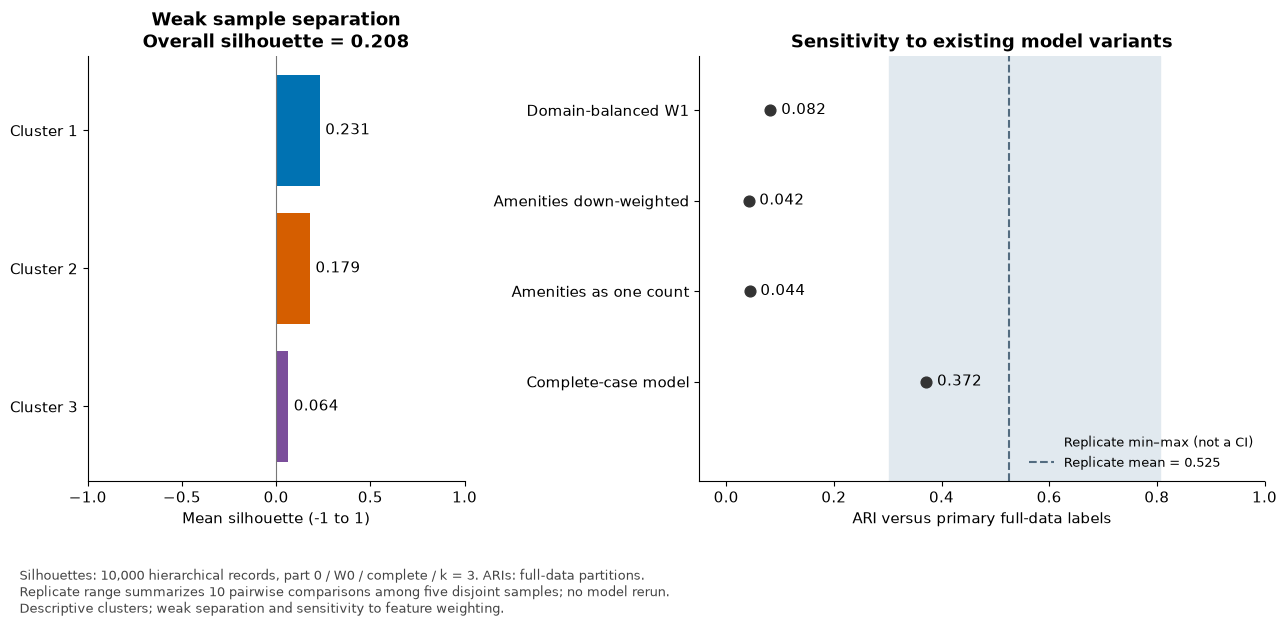

,size,mean_silhouette,negative_silhouette_pct
cluster,,,
1,6833,0.231,8.371
2,2594,0.179,12.452
3,573,0.064,32.286


Replicate ARI: mean 0.524515; min 0.301883; max 0.805311


In [22]:
primary_eval = evaluation.query("part == 0 and weighting == 'W0' and linkage == 'complete' and k_requested == 3")
assert len(primary_eval) == 1
mean_silhouette = float(primary_eval.iloc[0]["mean_silhouette"])
quality = per_cluster.query("part == 0 and weighting == 'W0' and linkage == 'complete' and k == 3").copy()
label_map = {int(k): int(v) for k, v in config["cluster_numbering"]["scipy_fcluster_label_to_final_cluster"].items()}
quality["cluster"] = quality["cluster"].map(label_map)
quality = quality.set_index("cluster").reindex(CLUSTERS)
assert quality["size"].tolist() == size_table["hierarchical"].tolist()
np.testing.assert_allclose(np.average(quality["mean_silhouette"], weights=quality["size"]), mean_silhouette, atol=1e-8)
replicate = stability.query("kind == 'replicate_stability' and linkage == 'complete' and k == 3")
assert len(replicate) == 10
ari_min, ari_mean, ari_max = replicate["ari"].min(), replicate["ari"].mean(), replicate["ari"].max()
sensitivity = stability.query("kind == 'sensitivity' and linkage == 'complete' and k == 3").set_index("comparison")
comparisons = {"W1 vs primary": "Domain-balanced W1", "W2_neighborhood_third vs primary": "Amenities down-weighted",
               "amenity_count vs primary": "Amenities as one count", "complete_case vs primary": "Complete-case model"}
sens_plot = sensitivity.loc[list(comparisons), "ari"]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.4), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].barh(np.arange(3), quality["mean_silhouette"], color=CLUSTER_COLORS)
for i, c in enumerate(CLUSTERS):
    value = quality.loc[c, "mean_silhouette"]
    axes[0].text(value + 0.03, i, f"{value:.3f}", va="center")
axes[0].axvline(0, color="#777777", linewidth=0.8)
axes[0].set(xlim=(-1, 1), xticks=[-1, -0.5, 0, 0.5, 1], yticks=np.arange(3), yticklabels=list(CLUSTER_NAMES.values()),
            xlabel="Mean silhouette (-1 to 1)", title=f"Weak sample separation\nOverall silhouette = {mean_silhouette:.3f}")
axes[0].invert_yaxis()
axes[1].axvspan(ari_min, ari_max, color="#E1E9EF", label="Replicate min–max (not a CI)")
axes[1].axvline(ari_mean, color="#536C80", linestyle="--", label=f"Replicate mean = {ari_mean:.3f}")
axes[1].scatter(sens_plot, np.arange(4), color="#333333", s=60, zorder=3)
for i, v in enumerate(sens_plot):
    axes[1].text(v + 0.02, i, f"{v:.3f}", va="center")
axes[1].set(xlim=(-0.05, 1), ylim=(4.1, -0.6), yticks=np.arange(4), yticklabels=list(comparisons.values()),
            xlabel="ARI versus primary full-data labels", title="Sensitivity to existing model variants")
axes[1].legend(loc="lower right", fontsize=9, frameon=False)
save_figure(fig, "05_model_limitations.png",
            "Silhouettes: 10,000 hierarchical records, part 0 / W0 / complete / k = 3. ARIs: full-data partitions.\n"
            "Replicate range summarizes 10 pairwise comparisons among five disjoint samples; no model rerun.")
quality_display = quality[["size", "mean_silhouette", "share_negative_silhouette"]].copy()
quality_display["negative_silhouette_pct"] = quality_display.pop("share_negative_silhouette") * 100
display(quality_display.round(3))
print(f"Replicate ARI: mean {ari_mean:.6f}; min {ari_min:.6f}; max {ari_max:.6f}")

In [23]:
# ---- Check descriptive differences between membership methods ------------
method_rows = []
for (c, method), group in data.groupby(["cluster", "assignment_method"]):
    screen = event_summary(group, "screentime", [5])
    med = event_summary(group, "k4q23", [1])
    method_rows.append({"cluster": c, "assignment_method": method, "n": len(group),
                        "screen_4plus_pct": screen["unweighted_pct"], "medication_pct": med["unweighted_pct"]})
method_profiles = pd.DataFrame(method_rows)
display(method_profiles.round(2))
assigned = data.loc[data["assignment_method"].eq("assigned")]
assert assigned["assignment_margin"].notna().all()
ambiguous_n = int(assigned["assignment_margin"].lt(0.02).sum())
display(Markdown(f"**Assignment margin below 0.02:** {ambiguous_n:,} / {len(assigned):,} assigned children "
                 f"(**{ambiguous_n / len(assigned) * 100:.1f}%**). This is a distance-margin flag, not an error probability."))

,cluster,assignment_method,n,screen_4plus_pct,medication_pct
0,1,assigned,26881,22.32,8.68
1,1,hierarchical,6833,23.27,10.33
2,2,assigned,11883,21.63,2.43
3,2,hierarchical,2594,20.35,1.85
4,3,assigned,2611,51.86,64.27
5,3,hierarchical,573,48.87,52.71


**Assignment margin below 0.02:** 2,439 / 41,375 assigned children (**5.9%**). This is a distance-margin flag, not an error probability.

### Insight 4 · Useful group descriptions have limited separation and stability

**Evidence:** the overall mean silhouette is 0.208; Cluster 3 has mean 0.064 and 32.3% negative silhouettes among its 573 hierarchical members. Mean replicate ARI is 0.525, with a 0.302–0.805 range. W1 and the two amenity variants fall below that range. Cluster 3's medication share is 52.7% in hierarchical members and 64.3% in assigned members; its 4+ hour share is 48.9% and 51.9%, respectively.

**Meaning and relevance:** the profiles help organize the observed combinations of screen use, environment and health, but the evidence does not support three sharply distinct population types. The full-data assignment rule makes some contrasts stronger, particularly medication in Cluster 3. Describing only the assigned profile would hide that difference.

**Practical implication:** communicate cluster numbers, denominators, age context and uncertainty together. Use these patterns to formulate follow-up questions and review support needs, not to classify an individual child's risk, recommend treatment, or allocate services. Future confirmation needs independent data, survey-aware analysis and variables not used to create the groups.

**Limitations:** the replicate ARIs compare full-data labels derived from the same finite survey, not independent external cohorts. Negative silhouettes and small assignment margins indicate overlap or ambiguity under this distance, not incorrect survey responses. The primary model remains the team's approved descriptive model despite these limitations.

## 7 · Ethical reflection

| Concern | Why it matters in this analysis | Practical mitigation |
|---|---|---|
| Children's privacy and re-identification | Records combine family, health and environment information with a stable `hhid`. Public-use status does not make arbitrary joins or fine-grained releases harmless. | Use `hhid` only for validated internal joins. Share aggregate plots/tables, never identifiable examples or new child-level extracts. Review small numerator cells and combinations before wider release; retain the team's minimum-denominator rule without treating it as a privacy guarantee. |
| Survey selection and representativeness | The team's NSCH documentation records oversampling of young children and children with special health care needs. Clustering and the form × screen-time subsampling are unweighted; matching that sample distribution does not remove survey selection bias. | Label counts as survey-sample descriptions; show the `fwc` comparison and keep denominators explicit. Future population inference should use the documented survey design, weights and design-based uncertainty, with independent replication. Do not present 6.2% as the national prevalence of a child “type.” |
| Missingness and unequal measurement | Mode imputation adds majority responses, including 868 screen-time values. The sleep indicator is undefined for 446 infants; a filled answer and a structurally unavailable answer carry different information. | Preserve the imputation flags, report variable-specific observed-only comparisons, and exclude undefined sleep values from its denominator. Future work should examine nonresponse by relevant groups and assess alternative missing-data methods before claiming fairness. Do not convert missing responses into zero or “healthy.” |
| Reporting bias and interpretation of care | Screen use, curiosity, amenity presence and health-care use are caregiver reports. Treatment and medication can reflect both need and access; their absence is not proof of absence of difficulty. | Use precise item wording and neutral labels. Future work can triangulate reports with ethically collected information about screen-use context and access, while minimizing collection of sensitive data. Keep “reported medication use” separate from diagnosis and avoid clinical advice from clusters. |
| Stigma and unfair use of cluster labels | Cluster 3 combines higher screen use, older ages and higher reported care use, but has the weakest separation. Calling it “addicted,” “unhealthy” or a “problem family” group would turn uncertain group averages into judgments about individuals. | Retain Cluster 1–3 labels; describe tendencies with age context and overlapping membership. Never use these labels alone to deny services, rank families or identify children for intervention. Any future service use needs separate validation, stakeholder review and fairness assessment across relevant groups. This notebook does not establish fairness. |
| Feature choices can encode priorities | Three correlated amenity inputs receive three separate W0 contributions, and existing weighting variants substantially change the partition. Low reported amenity availability can reflect structural circumstances rather than family choices. | Disclose the weighting dependence next to the plots. Avoid equating amenity presence with opportunity, safety or parental effort. Discuss structural barriers with affected communities before any policy interpretation; retain the approved model as descriptive work rather than silently replacing it. |
| Causal overinterpretation and inflated certainty | All plotted substantive variables helped construct the labels; cross-sectional co-occurrence and weak separation do not establish causal pathways. Assignment also changes the strength of some contrasts. | Pair screen time with age; show the age-band and membership-method tables, silhouettes and sensitivity evidence. Frame actions as questions for follow-up. Future causal questions require an appropriate design and measured confounders, while independent validation should use information not used to build the clusters. |

The defensible use of these results is to understand patterns in this survey and guide further inquiry. They do not provide a screening tool, medical recommendation or basis for judgments about individual children and families.

## 8 · Reproducibility and saved figures

All calculations above use `datasets/preprocessed_data.csv` and the six primary export/configuration files loaded in Section 1. Preprocessing and distance definitions are traced to notebooks 01 and 03; notebook 04 supplies context for the retained primary model. The tables expose counts and denominators, and the validation cells compare the new calculations against the approved profile export.

Only the five aggregate PNGs listed below are written by this notebook. Original notebooks, model outputs, cluster labels and the preprocessing data remain inputs.

In [24]:
assert len(SAVED_FIGURES) == 5 and len(set(SAVED_FIGURES)) == 5
assert all(path.is_file() and path.stat().st_size > 0 for path in SAVED_FIGURES)
for path in SAVED_FIGURES:
    print(path.relative_to(ROOT).as_posix())
print("Complete: validated profiles, five figures, evidence-based insights and ethical reflection.")

outputs/visualization_insights/01_cluster_sizes.png
outputs/visualization_insights/02_screen_time_and_age.png
outputs/visualization_insights/03_neighborhood_amenities.png
outputs/visualization_insights/04_health_lifestyle.png
outputs/visualization_insights/05_model_limitations.png
Complete: validated profiles, five figures, evidence-based insights and ethical reflection.
